Section 1 - Setup & Data Loading

This section installs the required tools, connects to Google Drive, and prepares the PTB-XL ECG data so the rest of the notebook can use it. The heavy one-time processing is cached, so later runs load the prepared data quickly rather than repeating it.

In [1]:
# Install wfdb — the WaveForm DataBase toolkit used to read
# -q = quiet install (suppresses pip's verbose output).

!pip install -q wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.5 MB/s eta 0:00:00


In [1]:
# Mount Google Drive so the notebook can read/write to cached dataset
# and model checkpoints, and figures.

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
# Copy the raw data to /content/

!cp "/content/ptbxl/records100.zip" "/content/"
!cp "/content/ptbxl/ptbxl_database.csv" "/content/"
!cp "/content/ptbxl/scp_statements.csv" "/content/"

In [17]:
# Move to Colab's local disk. Working here (not inside the Drive mount)
# keeps file reads fast — Drive access goes over the network and is far slower.

!cd /content/

In [18]:
# PTB-XL ships ECG waveforms at two sampling rates:
#   records100/ — 100 Hz  (used in this study)
#   records500/ — 500 Hz  (higher resolution; not used)
# This study uses the 100 Hz set: at the 5-superclass level it gives
# equivalent performance at ~1/5 the compute and storage cost.

!unzip records100  # 100 Hz — the data we use
#!unzip records500 # 500 Hz — available but unused


Streaming output truncated to the last 5000 lines.
  inflating: records100/19000/19339_lr.dat  
  inflating: records100/19000/19339_lr.hea  
  inflating: records100/19000/19340_lr.dat  
  inflating: records100/19000/19340_lr.hea  
  inflating: records100/19000/19341_lr.dat  
  inflating: records100/19000/19341_lr.hea  
  inflating: records100/19000/19342_lr.dat  
  inflating: records100/19000/19342_lr.hea  
  inflating: records100/19000/19343_lr.dat  
  inflating: records100/19000/19343_lr.hea  
  inflating: records100/19000/19344_lr.dat  
  inflating: records100/19000/19344_lr.hea  
  inflating: records100/19000/19345_lr.dat  
  inflating: records100/19000/19345_lr.hea  
  inflating: records100/19000/19346_lr.dat  
  inflating: records100/19000/19346_lr.hea  
  inflating: records100/19000/19347_lr.dat  
  inflating: records100/19000/19347_lr.hea  
  inflating: records100/19000/19348_lr.dat  
  inflating: records100/19000/19348_lr.hea  
  inflating: records100/19000/19349_lr.dat  
  in

Section 2 - Data Preparation

This section prepares the PTB-XL data for training. It builds the diagnostic labels from the raw SCP codes, loads the ECG signals into a single array, and inspects the data to confirm it has loaded correctly. The recordings are then filtered, encoded as multi-label targets, split into training, validation, and test sets using PTB-XL's patient-grouped folds, and standardised. Because the full loading step is slow, the prepared data is cached so later sessions can reload it in seconds.

In [29]:
# Verify the CSVs and the 100 Hz waveform folder are present before proceeding.

import os
PATH = '/content/'

print(os.path.exists(PATH + 'ptbxl_database.csv'))
print(os.path.exists(PATH + 'records100'))

True
True


In [28]:
# Build the diagnostic labels. PTB-XL stores each record's diagnosis as
# SCP codes. This maps those to the 5
# diagnostic SUPERCLASSES used for classification: NORM, MI, STTC, CD, HYP.

import pandas as pd, ast

Y = pd.read_csv(PATH + 'ptbxl_database.csv', index_col='ecg_id') # Load the
# record metadata table (one row per ECG)
Y.scp_codes = Y.scp_codes.apply(ast.literal_eval) # scp_codes is stored as a
# STRING that looks like a dict, e.g. "{'NORM': 100.0}".
# literal_eval safely parses that string into an actual Python dict.

# Load the SCP code dictionary, keep only DIAGNOSTIC statements
# scp_statements.csv maps each SCP code to its superclass.
agg = pd.read_csv(PATH + 'scp_statements.csv', index_col=0)
agg = agg[agg.diagnostic == 1]

# Map each record to its set of superclasses. A record can have several
# (e.g. MI + STTC) -> this is a multi-label problem, hence sigmoid + BCE used later.
def to_superclass(d):
    return sorted({agg.loc[k].diagnostic_class for k in d if k in agg.index})

Y['diagnostic_superclass'] = Y.scp_codes.apply(to_superclass)
Y['n_labels'] = Y.diagnostic_superclass.apply(len)

# Total records, label-count distribution, class frequencies.
print(Y.shape)
print(Y.n_labels.value_counts().sort_index())
print(Y.diagnostic_superclass.explode().value_counts())

(21799, 29)
n_labels
0      411
1    16244
2     4068
3      919
4      157
Name: count, dtype: int64
diagnostic_superclass
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
Name: count, dtype: int64


Interpretation:
Y.shape - around (21799, 29)

n_labels - a chunk of records with 0 labels (no diagnostic statement - I'll drop these) and plenty with 2 or more (this is why it's multi-label, not 5-way single-label)

Class counts - NORM dominates.

Diagnostic Classes

In [40]:
# The five diagnostic superclasses, pulled straight from the mapping.

diagnostic_codes = agg['diagnostic_class'].dropna().unique().tolist()

In [41]:
diagnostic_codes

['STTC', 'NORM', 'MI', 'HYP', 'CD']

In [31]:
# Columns and few values in Y
Y.head()

,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,diagnostic_superclass,n_labels
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr,[NORM],1
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr,[NORM],1
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr,[NORM],1
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr,[NORM],1
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr,[NORM],1


In [30]:
# Columns and few values in agg
agg.head()

,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


In [38]:
Y.columns # list available metadata fields

Index(['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site',
       'device', 'recording_date', 'report', 'scp_codes', 'heart_axis',
       'infarction_stadium1', 'infarction_stadium2', 'validated_by',
       'second_opinion', 'initial_autogenerated_report', 'validated_by_human',
       'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
       'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr',
       'diagnostic_superclass', 'n_labels'],
      dtype='object')

In [39]:
agg.columns # available fields in the SCP mapping

Index(['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class',
       'diagnostic_subclass', 'Statement Category',
       'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code',
       'DICOM Code'],
      dtype='object')

Plotting 1 Lead

(1000, 12)
['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


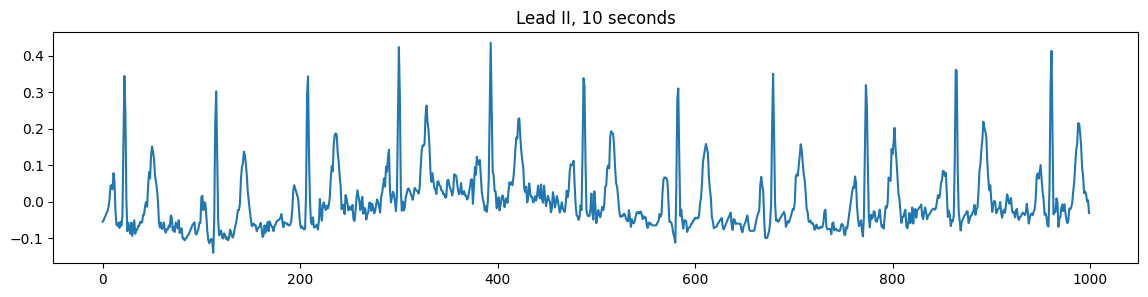

In [ ]:
# Load and plot one raw record to confirm the signals read correctly.
# Each record is 10 sec x 12 leads at 100 Hz, shape (1000, 12), in millivolts.
import wfdb, matplotlib.pyplot as plt

sig, meta = wfdb.rdsamp(PATH + Y.filename_lr.iloc[0])
print(sig.shape)          # expect (1000, 12)
print(meta['sig_name'])   # expect ['I','II','III','AVR',...,'V6']

plt.figure(figsize=(14, 3))
plt.plot(sig[:, 1])       # Lead II
plt.title('Lead II, 10 seconds')
plt.show()

Plotting all 12 Leads

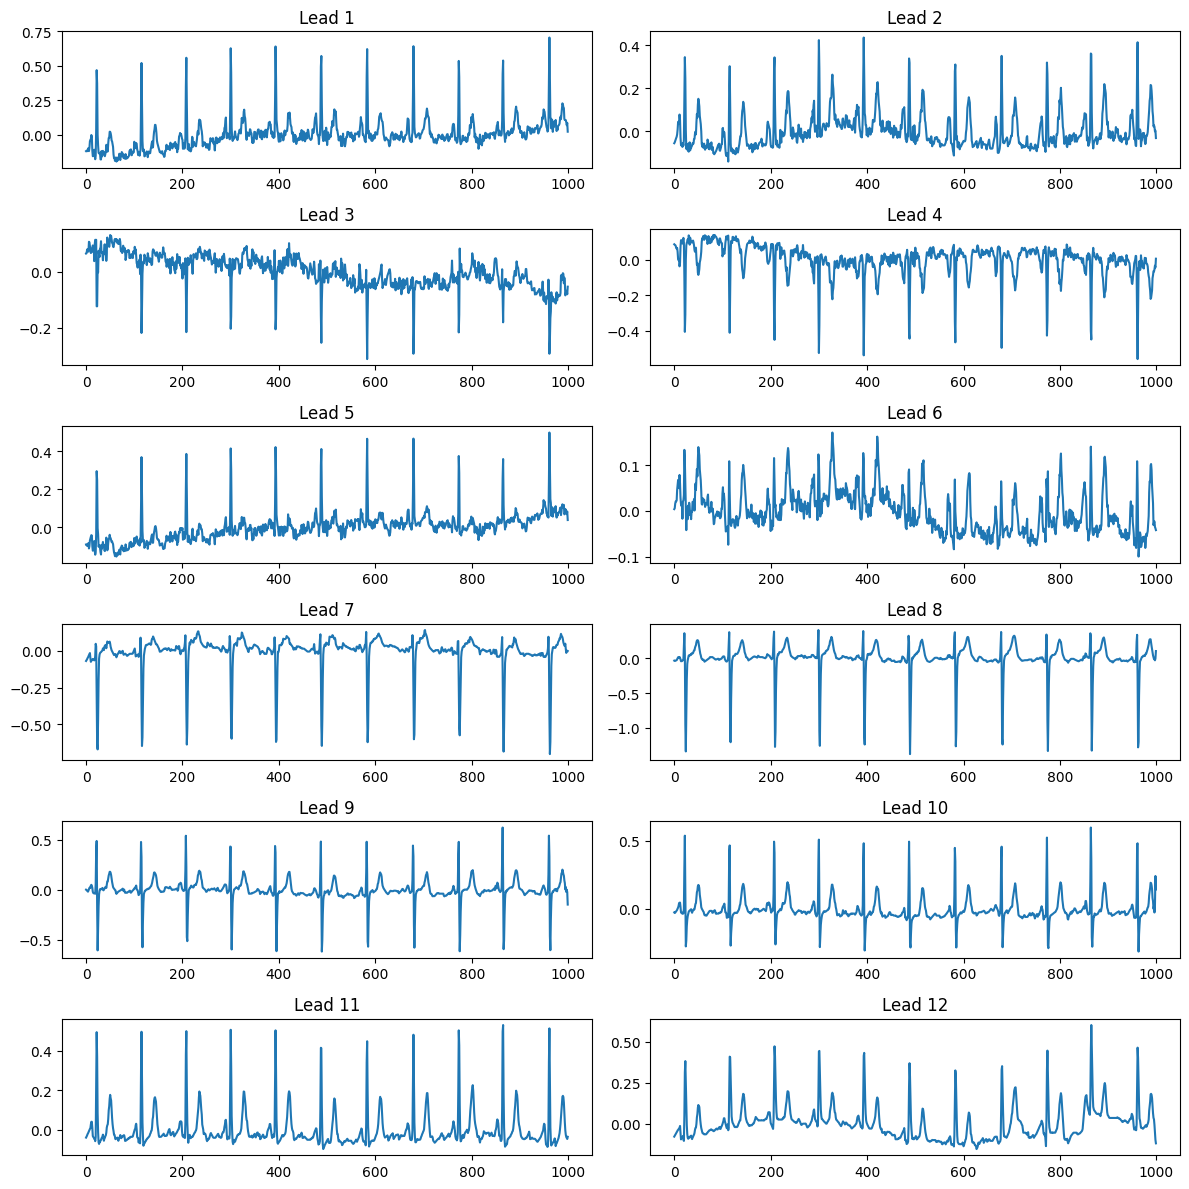

In [35]:
# Plot all 12 leads of one record to visualise a complete ECG.

import wfdb, matplotlib.pyplot as plt
import numpy as np

signal, meta = wfdb.rdsamp(PATH + Y.filename_lr.iloc[0])

plt.figure(figsize=(12,12))
for i in range(signal.shape[1]):
    plt.subplot(6,2,i+1)
    plt.plot(signal[:,i])
    plt.title(f"Lead {i+1}")
    plt.tight_layout()
plt.show()

Cache all signals into one file

This is the slow part. It is done to cache all the signals into a file. Next time I'll just load from cache.



In [21]:
# Load all waveforms into one array. We read the raw .dat files directly with
# numpy rather than wfdb.rdsamp — ~10-20x faster across 21,799 records.
# Conversion to millivolts is done manually using the gain/baseline from the
# header: mV = (raw_int16 - baseline) / gain.

import numpy as np, wfdb
from tqdm import tqdm

# Read one header to get the format constants.
hdr  = wfdb.rdheader(PATH + Y.filename_lr.iloc[0])
GAIN = np.array(hdr.adc_gain, dtype=np.float32)
BASE = np.array(hdr.baseline, dtype=np.float32)
N, L = hdr.n_sig, hdr.sig_len  # 12 leads, 1000 samples

# float16 halves memory; ample precision for mV-scale ECG.

X, bad = np.zeros((len(Y), L, N), dtype=np.float16), []

for i, f in enumerate(tqdm(Y.filename_lr)):
    raw = np.fromfile(PATH + f + '.dat', dtype='<i2')
    if raw.size != L * N:
        bad.append(i); continue
    X[i] = (raw.reshape(-1, N).astype(np.float32) - BASE) / GAIN

print('failed:', len(bad))

100%|██████████| 21799/21799 [00:04<00:00, 4962.07it/s]

failed: 0


In [ ]:
# Verify the fast numpy reader against wfdb.rdsamp on a few records.
# All should print True -> confirms the manual mV conversion (gain/baseline,
# byte order) is correct.

for i in [0, 500, 10000, 21000]:
    ref, _ = wfdb.rdsamp(PATH + Y.filename_lr.iloc[i])
    print(i, np.allclose(ref, X[i].astype(np.float32), atol=1e-3))

0 True
500 True
10000 True
21000 True


In [22]:
# save X and Y locally first, then copy to Drive
# (saving straight to Drive is really slow and sometimes fails)

np.save('/content/ptbxl_X_100hz.npy', X)
Y.to_pickle('/content/ptbxl_Y.pkl')

!mkdir -p "/content/drive/MyDrive/ptbxl_cache"
!cp /content/ptbxl_X_100hz.npy /content/ptbxl_Y.pkl "/content/drive/MyDrive/ptbxl_cache/"
!ls -lh "/content/drive/MyDrive/ptbxl_cache/" # check the files copied (X should be about 0.5 GB)

total 1.1G
-rw------- 1 root root 4.9M Aug 31 14:22 c1_baseline.pt
-rw------- 1 root root 1.4K Aug 31 14:22 c1_meta.json
-rw------- 1 root root  164 Aug 31 14:22 c1_results.csv
-rw------- 1 root root 4.9M Aug 31 15:38 C1_s1.pt
-rw------- 1 root root 4.9M Aug 31 15:40 C1_s2.pt
-rw------- 1 root root 4.9M Aug 31 15:35 C1_s42.pt
-rw------- 1 root root 4.9M Aug 31 16:37 F2_s1.pt
-rw------- 1 root root 4.9M Aug 31 16:41 F2_s2.pt
-rw------- 1 root root 4.9M Aug 31 16:32 F2_s42.pt
-rw------- 1 root root 4.9M Sep  2 14:08 F3_s1.pt
-rw------- 1 root root 4.9M Sep  2 14:14 F3_s2.pt
-rw------- 1 root root 4.9M Aug 31 16:56 F3_s42.pt
-rw------- 1 root root 4.9M Sep  2 17:22 F5_s1.pt
-rw------- 1 root root 4.9M Sep  2 19:02 F5_s2.pt
-rw------- 1 root root 4.9M Sep  2 16:07 F5_s42.pt
-rw------- 1 root root 4.9M Sep  2 18:33 F6_s1.pt
-rw------- 1 root root 4.9M Sep  2 19:59 F6_s2.pt
-rw------- 1 root root 4.9M Sep  2 16:44 F6_s42.pt
-rw------- 1 root root 132K Sep  7 14:09 fig_all_configs.png
-rw----

Turn the cached arrays into model-ready tensors

Four small operations, then we are ready to train.
1. Dropped the records with non diagnostic label
2. One hot encoding
3. Splitting into train, test and validation
4. Standardisation of train set

In [ ]:
import numpy as np, pandas as pd

CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

# drop records with no diagnostic label

mask = (Y.n_labels > 0).values
print('dropped:', (~mask).sum(), '| kept:', mask.sum())
Xf = X[mask]
Yf = Y[mask].copy().reset_index()

# the model can't read 'MI' or 'STTC', it needs numbers. so each record
# becomes a row of five 0s/1s - a 1 for every condition it has.
# one record can have more than one 1 (multi-label), which is why we do
# it this way instead of a single class number.
y = np.zeros((len(Yf), 5), dtype=np.float32)
for i, labs in enumerate(Yf.diagnostic_superclass):
    for l in labs:
        y[i, CLASSES.index(l)] = 1.0

# 3. use PTB-XL's official split: folds 1-8 train, 9 validation, 10 test.
# it's split by patient, so the same person never appears in two sets.

tr = (Yf.strat_fold <= 8).values
va = (Yf.strat_fold == 9).values
te = (Yf.strat_fold == 10).values
print('train/val/test:', tr.sum(), va.sum(), te.sum())

# standardise each lead (subtract mean, divide by std).
# IMPORTANT: stats come from the TRAIN set only - using val/test here would
# leak information and inflate the results.

mu = Xf[tr].astype(np.float32).mean(axis=(0, 1))
sd = Xf[tr].astype(np.float32).std(axis=(0, 1))
print('mu:', mu.round(3))
print('sd:', sd.round(3))

dropped: 411 | kept: 21388
train/val/test: 17084 2146 2158
mu: [-0.002 -0.002  0.     0.002 -0.001 -0.001  0.    -0.001 -0.002 -0.001
 -0.001 -0.002]
sd: [0.156 0.155 0.156 0.135 0.136 0.135 0.23  0.329 0.322 0.286 0.266 0.276]


Sanity Checks

In [3]:
print(y.sum(axis=0))                      # records per class
print((y.sum(axis=1)).mean())             # avg labels per record
print(pd.DataFrame(y, columns=CLASSES).corr().round(2))   # co-occurrence
print('patients:', Yf.patient_id.nunique(), '| records:', len(Yf))
print(Yf[Yf.age < 100].age.describe().round(1))
print(Yf.sex.value_counts())              # 0 = male, 1 = female

[9514. 5469. 5235. 4898. 2649.]
1.2981578
      NORM    MI  STTC    CD   HYP
NORM  1.00 -0.52 -0.50 -0.39 -0.34
MI   -0.52  1.00  0.00  0.14  0.05
STTC -0.50  0.00  1.00 -0.03  0.28
CD   -0.39  0.14 -0.03  1.00  0.06
HYP  -0.34  0.05  0.28  0.06  1.00
patients: 18617 | records: 21388
count    21103.0
mean        59.4
std         16.8
min          2.0
25%         50.0
50%         61.0
75%         72.0
max         89.0
Name: age, dtype: float64
sex
0    11111
1    10277
Name: count, dtype: int64


Class Distribution Plot

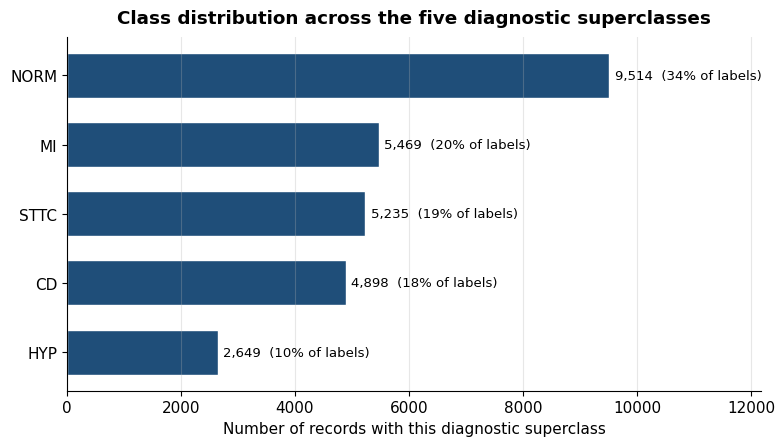

In [4]:
import matplotlib.pyplot as plt, numpy as np
plt.rcParams.update({'font.family':'sans-serif','font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False})

classes = ['NORM','MI','STTC','CD','HYP']
counts  = list(y.sum(axis=0).astype(int))        # YOUR real counts

order = np.argsort(counts)[::-1]
classes = [classes[i] for i in order]; counts = [counts[i] for i in order]
total = sum(counts)

fig, ax = plt.subplots(figsize=(8,4.6))
bars = ax.barh(classes, counts, color='#1f4e79', edgecolor='white', height=0.65)
ax.invert_yaxis()
for b,c in zip(bars,counts):
    ax.text(c+max(counts)*0.01, b.get_y()+b.get_height()/2,
            f'{c:,}  ({100*c/total:.0f}% of labels)', va='center', fontsize=9.5)
ax.set_xlabel('Number of records with this diagnostic superclass')
ax.set_title('Class distribution across the five diagnostic superclasses', fontweight='bold', pad=10)
ax.set_xlim(0, max(counts)*1.28); ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/ptbxl_cache/fig_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

Saving the processed version

In [ ]:
# save the processed data so I don't have to redo all of the above every time
# local first, then copy to Drive (Drive writes are slow / can fail)

np.save('/content/X_proc.npy', Xf)
np.save('/content/y.npy', y)
np.savez('/content/splits.npz', tr=tr, va=va, te=te, mu=mu, sd=sd)
Yf.to_pickle('/content/Yf.pkl')
!cp /content/X_proc.npy /content/y.npy /content/splits.npz /content/Yf.pkl "/content/drive/MyDrive/ptbxl_cache/"

Loading from Cache. Future sessions will load from below.

In [24]:
# load the data from Cache
X = np.load('/content/drive/MyDrive/ptbxl_cache/ptbxl_X_100hz.npy')
Y = pd.read_pickle('/content/drive/MyDrive/ptbxl_cache/ptbxl_Y.pkl')

Section 3 - Model Definition

This section defines the model used for classification: a one-dimensional convolutional neural network with a residual design. It also sets up the dataset wrapper that feeds data to the model, standardising each recording and reshaping it into the layout the convolutional layers expect i.e from (B, 12, 1000) to (N, 1000, 12).


Setup and Loaders

Centralised Run from here.




In [ ]:
import numpy as np, pandas as pd, torch, torch.nn as nn, random
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, f1_score

# fix the random seed so results are repeatable (same run gives same numbers)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev)      # must say cuda — Runtime → Change runtime type → GPU

CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

# feeds data to the model one batch at a time. standardises each signal and
# flips it to (leads, time) - the shape the conv layers expect.

class ECG(Dataset):
    def __init__(self, X, y, idx, mu, sd):
        self.X, self.y = X, y
        self.idx = np.where(idx)[0]
        self.mu, self.sd = mu.astype(np.float32), sd.astype(np.float32)
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = (self.X[j].astype(np.float32) - self.mu) / self.sd
        return torch.from_numpy(x.T.copy()), torch.from_numpy(self.y[j])

# small helper to build a train/val/test loader
def loader(idx, shuffle):
    return DataLoader(ECG(Xf, y, idx, mu, sd), batch_size=128,
                      shuffle=shuffle, num_workers=2, pin_memory=True, drop_last=shuffle)

dl_tr, dl_va, dl_te = loader(tr, True), loader(va, False), loader(te, False)

xb, yb = next(iter(dl_tr))
print(xb.shape, yb.shape)   # MUST be [128, 12, 1000] and [128, 5]

device: cpu


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


torch.Size([128, 12, 1000]) torch.Size([128, 5])


ECGNet Model

In [ ]:
# the model: a 1D CNN (ResNet-style) for classifying the 12-lead ECG.
# 1D convolutions slide along the time axis and pick up the shapes in the
# heartbeat; the skip connections let me stack more layers without training
# getting stuck.

import torch.nn as nn
class Block(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv1d(cin, cout, 7, stride, 3, bias=False)
        self.n1 = nn.GroupNorm(8, cout)
        self.c2 = nn.Conv1d(cout, cout, 7, 1, 3, bias=False)
        self.n2 = nn.GroupNorm(8, cout)
        self.act = nn.ReLU(inplace=False) # inplace=False is required later for the privacy library
        self.drop = nn.Dropout(0.1)
        self.skip = nn.Sequential()
        # if the shape changes, the shortcut needs a 1x1 conv to match it
        if stride != 1 or cin != cout:
            self.skip = nn.Sequential(nn.Conv1d(cin, cout, 1, stride, bias=False),
                                      nn.GroupNorm(8, cout))
    def forward(self, x):
        r = self.skip(x)
        x = self.act(self.n1(self.c1(x)))
        x = self.drop(x)
        x = self.n2(self.c2(x))
        return self.act(x + r)

class ECGNet(nn.Module):
    def __init__(self, n_leads=12, n_cls=5, w=(32, 64, 128, 256)):
        super().__init__()
        # first layer: shrink the signal a bit and expand to 32 channels
        self.stem = nn.Sequential(
            nn.Conv1d(n_leads, w[0], 15, 2, 7, bias=False),
            nn.GroupNorm(8, w[0]), nn.ReLU(inplace=False), nn.MaxPool1d(3, 2, 1))
        # stack of blocks, widening 32 - 64 - 128 -> 256 as it goes deeper
        self.body = nn.Sequential(
            Block(w[0], w[0]), Block(w[0], w[1], 2),
            Block(w[1], w[1]), Block(w[1], w[2], 2),
            Block(w[2], w[2]), Block(w[2], w[3], 2))
         # pool down to one value per channel, then a linear layer - 5 scores
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(),
                                  nn.Dropout(0.2), nn.Linear(w[3], n_cls))
    def forward(self, x):
        return self.head(self.body(self.stem(x)))

m = ECGNet().to(dev)
P = sum(p.numel() for p in m.parameters())
print(f'params: {P:,}  ({P*4/1e6:.2f} MB fp32)')
print(m(xb.to(dev)).shape)   # [128, 5]

params: 1,257,925  (5.03 MB fp32)
torch.Size([128, 5])


Section 4 - Training & Evaluation

In [ ]:
# returns AUROC per class and the average (macro-AUROC).
# sigmoid turns the raw outputs into 0-1 probabilities.
# using AUROC not accuracy because the classes are imbalanced.

@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    P_, Y_ = [], []
    for xb, yb in dl:
        P_.append(torch.sigmoid(model(xb.to(dev))).cpu().numpy())
        Y_.append(yb.numpy())
    p, t = np.concatenate(P_), np.concatenate(Y_)
    per = [roc_auc_score(t[:, i], p[:, i]) for i in range(5)]
    return float(np.mean(per)), per, p, t

# standard training loop. trains for a number of epochs, checks the validation
# score each epoch, and keeps the best version (not just the last one).

def train(model, dl_tr, dl_va, epochs=30, lr=1e-3, tag='c1'):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, epochs*len(dl_tr), pct_start=0.3)
    lossf = nn.BCEWithLogitsLoss() # the right loss for multi-label (each class judged separately)
    best, hist = 0, []
    for ep in range(epochs):
        model.train(); tot = 0
        for xb, yb in dl_tr:
            xb, yb = xb.to(dev, non_blocking=True), yb.to(dev, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            l = lossf(model(xb), yb)
            l.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); sch.step()
            tot += l.item()
        auc, _, _, _ = evaluate(model, dl_va)
        hist.append((tot/len(dl_tr), auc))
        if auc > best:
            best = auc; torch.save(model.state_dict(), f'/content/{tag}.pt')
        print(f'ep {ep+1:02d}  loss {tot/len(dl_tr):.4f}  val_auc {auc:.4f}'
              f'{"  *" if auc == best else ""}')
    model.load_state_dict(torch.load(f'/content/{tag}.pt')) # reload the best one before returning
    return model, best, hist

Running the training set

In [ ]:
# quick sanity run - just to show one model trains and hits a sensible score.
# the real experiments (with seeds + logging) are done by run() below.

model = ECGNet().to(dev)
model, best_va, hist = train(model, dl_tr, dl_va, epochs=30)
print('best val macro-AUROC:', round(best_va, 4))

ep 01  loss 0.5007  val_auc 0.8258  *
ep 02  loss 0.3806  val_auc 0.8474  *
ep 03  loss 0.3580  val_auc 0.8594  *
ep 04  loss 0.3449  val_auc 0.8690  *
ep 05  loss 0.3325  val_auc 0.8695  *
ep 06  loss 0.3235  val_auc 0.8822  *
ep 07  loss 0.3201  val_auc 0.8818
ep 08  loss 0.3104  val_auc 0.8868  *
ep 09  loss 0.3048  val_auc 0.8883  *
ep 10  loss 0.2947  val_auc 0.8923  *
ep 11  loss 0.2907  val_auc 0.8939  *
ep 12  loss 0.2810  val_auc 0.9000  *
ep 13  loss 0.2769  val_auc 0.8996
ep 14  loss 0.2704  val_auc 0.8987
ep 15  loss 0.2668  val_auc 0.9037  *
ep 16  loss 0.2607  val_auc 0.9010
ep 17  loss 0.2560  val_auc 0.9019
ep 18  loss 0.2499  val_auc 0.9037  *
ep 19  loss 0.2460  val_auc 0.9067  *
ep 20  loss 0.2442  val_auc 0.9048
ep 21  loss 0.2332  val_auc 0.9090  *
ep 22  loss 0.2268  val_auc 0.9051
ep 23  loss 0.2221  val_auc 0.9063
ep 24  loss 0.2148  val_auc 0.9074
ep 25  loss 0.2089  val_auc 0.9076
ep 26  loss 0.2004  val_auc 0.9082
ep 27  loss 0.1957  val_auc 0.9079
ep 28  los

Test set, once without Seeded setup

In [ ]:
# evaluate the trained model on the test set
auc, per, p, t = evaluate(model, dl_te)

# thresholds tuned on VALIDATION, applied to test
# pick a decision threshold per class using the VALIDATION set, then apply it
# to the test set. tuning thresholds on test itself would be cheating, so I
# only ever look at validation to choose them.
_, _, pv, tv = evaluate(model, dl_va)
th = [max(np.arange(0.05, 0.95, 0.01),
          key=lambda c: f1_score(tv[:, i], pv[:, i] > c, zero_division=0))
      for i in range(5)]

# turn probabilities into 0/1 predictions using those thresholds, then build
# a results table: how many test cases per class, AUROC, F1, and the threshold used.
pred = (p > np.array(th)).astype(int)
res = pd.DataFrame({
    'class':   CLASSES,
    'n_test':  t.sum(0).astype(int),
    'AUROC':   np.round(per, 4),
    'F1':      [round(f1_score(t[:, i], pred[:, i], zero_division=0), 4) for i in range(5)],
    'thresh':  np.round(th, 2)})
print(res.to_string(index=False))
print(f'\nMACRO AUROC {auc:.4f}   MACRO F1 {res.F1.mean():.4f}')

class  n_test  AUROC     F1  thresh
 NORM     963 0.9384 0.8535    0.57
   MI     550 0.9123 0.7274    0.21
 STTC     521 0.9299 0.7421    0.25
   CD     496 0.9176 0.7534    0.24
  HYP     262 0.8251 0.4848    0.26

MACRO AUROC 0.9047   MACRO F1 0.7122


Interpretation: Marco AUROC is more than .90.

NORM highest (0.94), HYP lowest (~0.83) - it's the rarest. F1 will look much weaker than AUROC on HYP. That's the imbalance.

Saving the model response in cache

In [ ]:
import json
torch.save(model.state_dict(), '/content/drive/MyDrive/ptbxl_cache/c1_baseline.pt')
res.to_csv('/content/drive/MyDrive/ptbxl_cache/c1_results.csv', index=False)
json.dump({'macro_auroc': auc, 'params': P, 'hist': hist},
          open('/content/drive/MyDrive/ptbxl_cache/c1_meta.json', 'w'))

Seeded Setup for Centralised and Local Baseline Models

Loader and Logging into Cache methods

In [ ]:
import numpy as np, torch, random, json, os
from torch.utils.data import DataLoader

# all results get appended to this one file, so I can load them all at the end
LOG = '/content/drive/MyDrive/ptbxl_cache/results.jsonl'

# set every random seed so a run is repeatable
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

# build the loaders for a given seed. the generator makes the batch shuffling
# repeatable too - without it, "same seed" wouldn't actually give the same run.
def make_loaders(seed):
    g = torch.Generator(); g.manual_seed(seed)
    def dl(idx, sh):
        return DataLoader(ECG(Xf, y, idx, mu, sd), batch_size=128, shuffle=sh,
                          num_workers=2, pin_memory=True, drop_last=sh,
                          generator=g if sh else None)
    return dl(tr, True), dl(va, False), dl(te, False)

def log(rec):
    with open(LOG, 'a') as f:
        f.write(json.dumps(rec) + '\n')

def already_done(config, seed):
    if not os.path.exists(LOG): return False
    return any(json.loads(l)['config'] == config and json.loads(l)['seed'] == seed
               for l in open(LOG))

run() method to run the model

In [ ]:
from sklearn.metrics import f1_score

# runs one full experiment for a given config + seed:
# train -> evaluate on test -> pick thresholds on validation -> log the results.
# train_idx lets me change which records to train on (used for the local-only
# and federated experiments); default is the full training set.
def run(config='C1', seed=42, epochs=30, train_idx=None, force=False):
    if already_done(config, seed) and not force:
        print(f'{config} seed {seed} already done — skipping'); return
    set_seed(seed)
    ti = tr if train_idx is None else train_idx
    g = torch.Generator(); g.manual_seed(seed)
    dtr = DataLoader(ECG(Xf, y, ti, mu, sd), 128, shuffle=True, num_workers=2,
                     pin_memory=True, drop_last=True, generator=g)
    dva, dte = make_loaders(seed)[1:]

    model = ECGNet().to(dev)
    P = sum(p.numel() for p in model.parameters())
    model, best_va, hist = train(model, dtr, dva, epochs=epochs,
                                 tag=f'{config}_s{seed}')

    # test score + per-class scores
    auc, per, p, t = evaluate(model, dte)
    # thresholds from validation only (not test), same as before
    _, _, pv, tv = evaluate(model, dva)
    th = [max(np.arange(0.05, 0.95, 0.01),
              key=lambda c: f1_score(tv[:, i], pv[:, i] > c, zero_division=0))
          for i in range(5)]
    pred = (p > np.array(th)).astype(int)
    f1 = [f1_score(t[:, i], pred[:, i], zero_division=0) for i in range(5)]

    # save everything to the log and save the model weights
    log({'config': config, 'seed': seed, 'n_train': int(ti.sum()),
         'macro_auroc': auc, 'macro_f1': float(np.mean(f1)),
         'per_class_auroc': [float(v) for v in per],
         'per_class_f1': [float(v) for v in f1],
         'best_val_auroc': best_va, 'params': P, 'epochs': epochs,
         'val_thresholds': [float(v) for v in th]})
    torch.save(model.state_dict(),
               f'/content/drive/MyDrive/ptbxl_cache/{config}_s{seed}.pt')
    print(f'{config} seed {seed}: macro-AUROC {auc:.4f}  macro-F1 {np.mean(f1):.4f}')

Section 5 - Experiment 1: Centralised Baseline (C1)

This trains a single model on all the training data at once, with no privacy and no splitting across clients.

 It represents the situation where every hospital shares its raw data to one central server - not realistic for patient privacy, but it gives the highest accuracy the model can reach. Every later experiment is measured against this as the upper bound. I run three random seeds and report the mean.

In [ ]:
#5. EXPERIMENT 1 - CENTRALISED BASELINE (C1)
# train on ALL the data pooled together, no privacy, no federation.
# this is the best-case score - everything else gets compared against it.
# run 3 seeds so I can report an average and see how much it varies.
for s in [42, 1, 2]:
    run('C1', s)

ep 01  loss 0.5025  val_auc 0.8068  *
ep 02  loss 0.3915  val_auc 0.8465  *
ep 03  loss 0.3711  val_auc 0.8549  *
ep 04  loss 0.3502  val_auc 0.8633  *
ep 05  loss 0.3318  val_auc 0.8761  *
ep 06  loss 0.3179  val_auc 0.8798  *
ep 07  loss 0.3189  val_auc 0.8828  *
ep 08  loss 0.3136  val_auc 0.8870  *
ep 09  loss 0.3022  val_auc 0.8876  *
ep 10  loss 0.2945  val_auc 0.8917  *
ep 11  loss 0.2863  val_auc 0.8988  *
ep 12  loss 0.2822  val_auc 0.8997  *
ep 13  loss 0.2766  val_auc 0.9027  *
ep 14  loss 0.2708  val_auc 0.9025
ep 15  loss 0.2672  val_auc 0.9013
ep 16  loss 0.2631  val_auc 0.9050  *
ep 17  loss 0.2576  val_auc 0.9054  *
ep 18  loss 0.2534  val_auc 0.9040
ep 19  loss 0.2457  val_auc 0.9080  *
ep 20  loss 0.2419  val_auc 0.9048
ep 21  loss 0.2357  val_auc 0.9071
ep 22  loss 0.2299  val_auc 0.9080  *
ep 23  loss 0.2213  val_auc 0.9051
ep 24  loss 0.2156  val_auc 0.9078
ep 25  loss 0.2088  val_auc 0.9072
ep 26  loss 0.2006  val_auc 0.9064
ep 27  loss 0.1957  val_auc 0.9063
ep 2

To verify all the 3 Seeds results are present in the results cache file.

In [ ]:
# check what's finished so far and the average score per config
import pandas as pd
d = pd.read_json(LOG, lines=True)
print(d[['config','seed','macro_auroc','macro_f1']])
print(d.groupby('config').macro_auroc.agg(['mean','std','count']).round(4))

  config  seed  macro_auroc  macro_f1
0     C1    42     0.904483  0.714579
1     C1     1     0.904940  0.711861
2     C1     2     0.907775  0.713629
          mean     std  count
config                       
C1      0.9057  0.0018      3


Interpretation: STD is 0.0018 which is quite low so the 3 seeded runs are enough to move to the next step.

Section 6 - Experiment 2: Local-Only Baseline (L1)

Trains on just one hospital's data (site 0), nothing shared.



In [ ]:
# this is the worst-case - what a single hospital gets on its own.
# the gap between this and C1 is what there is to gain by working together.

# pick site 0's records, but only from the training folds
site0 = tr & (Yf.site == 0.0).values
print('L1 train records:', site0.sum())

for s in [42, 1, 2]:
    run('L1', s, train_idx=site0)

L1 train records: 7691
ep 01  loss 0.5455  val_auc 0.7583  *
ep 02  loss 0.4283  val_auc 0.8089  *
ep 03  loss 0.3741  val_auc 0.8325  *
ep 04  loss 0.3597  val_auc 0.8450  *
ep 05  loss 0.3429  val_auc 0.8464  *
ep 06  loss 0.3266  val_auc 0.8616  *
ep 07  loss 0.3196  val_auc 0.8599
ep 08  loss 0.3031  val_auc 0.8617  *
ep 09  loss 0.3005  val_auc 0.8708  *
ep 10  loss 0.2990  val_auc 0.8690
ep 11  loss 0.2768  val_auc 0.8715  *
ep 12  loss 0.2745  val_auc 0.8729  *
ep 13  loss 0.2693  val_auc 0.8794  *
ep 14  loss 0.2558  val_auc 0.8787
ep 15  loss 0.2485  val_auc 0.8821  *
ep 16  loss 0.2539  val_auc 0.8817
ep 17  loss 0.2413  val_auc 0.8849  *
ep 18  loss 0.2297  val_auc 0.8794
ep 19  loss 0.2236  val_auc 0.8909  *
ep 20  loss 0.2206  val_auc 0.8869
ep 21  loss 0.2174  val_auc 0.8888
ep 22  loss 0.2030  val_auc 0.8868
ep 23  loss 0.1999  val_auc 0.8875
ep 24  loss 0.1926  val_auc 0.8865
ep 25  loss 0.1842  val_auc 0.8853
ep 26  loss 0.1803  val_auc 0.8836
ep 27  loss 0.1728  val_a

Per class breakdown since HYP is the rarest class

In [ ]:
# check L1 finished and compare against C1 - overall and per class
d = pd.read_json(LOG, lines=True)
print(d.groupby('config').macro_auroc.agg(['mean','std']).round(4))
print(d.groupby('config').per_class_auroc.apply(
    lambda s: pd.Series(np.mean(np.vstack(s),0), index=CLASSES)).round(4))

          mean     std
config                
C1      0.9057  0.0018
L1      0.8856  0.0014
config      
C1      NORM    0.9392
        MI      0.9133
        STTC    0.9318
        CD      0.9160
        HYP     0.8283
L1      NORM    0.9305
        MI      0.8841
        STTC    0.9166
        CD      0.8988
        HYP     0.7979
Name: per_class_auroc, dtype: float64


Interpretation:
C1 0.9057 ± 0.0018 vs L1 0.8856 ± 0.0014. Gap of 0.020, roughly 12× your seed noise. That's unambiguous - one hospital training alone loses real diagnostic performance.

Rarest class suffers most, commonest suffers least - a 3.4× spread.

Loading everything from cache for Federated Learning

In [1]:
# --- restart point: run this to reload everything on a fresh session ---
# (skips all the preprocessing above - loads the saved cache instead)
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd
C = '/content/drive/MyDrive/ptbxl_cache/'

Xf = np.load(C + 'X_proc.npy')
y  = np.load(C + 'y.npy')
s  = np.load(C + 'splits.npz')
tr, va, te, mu, sd = s['tr'], s['va'], s['te'], s['mu'], s['sd']
Yf = pd.read_pickle(C + 'Yf.pkl')

print(Xf.shape, y.shape)
print('train/val/test:', tr.sum(), va.sum(), te.sum())
print('mu:', mu.round(3))

Mounted at /content/drive
(21388, 1000, 12) (21388, 5)
train/val/test: 17084 2146 2158
mu: [-0.002 -0.002  0.     0.002 -0.001 -0.001  0.    -0.001 -0.002 -0.001
 -0.001 -0.002]


Interpretation: 17048 training ECG recordings

Each recording has 1000 time samples

Each sample has 12 channels (12 ECG leads)

Section 7 - Federated Learning

This section implements federated learning, where the data is split across several clients - each standing in for a hospital - that train locally and share only their model updates, never the raw data. It defines how the data is partitioned into clients, how each client trains, and how their models are averaged into a single shared model (Federated Averaging), along with the loop that runs a complete federated experiment.

In [4]:
# FEDERATED LEARNING

# the idea: instead of pooling all data, split it across "clients" (virtual
# hospitals). each client trains on its own data, then we just average the
# models together. the raw data never leaves the client.

import copy, torch, numpy as np
from torch.utils.data import DataLoader

# split the training data into clients (returns one True/False mask each).
# 'site' - use the real hospital sites (3 big ones + the rest pooled)
# 'dirichlet' - make fake clients with deliberately uneven class mixes,
#                so I can test what happens when data is very non-uniform

def build_clients(kind='site', n=5, alpha=0.5, seed=42):
    """Returns list of boolean masks, one per client, all within tr."""
    if kind == 'site':
        cl = []
        for s in [0.0, 1.0, 2.0]:
            cl.append(tr & (Yf.site == s).values)
        rest = tr & ~np.any(cl, axis=0)
        if rest.sum() > 0: cl.append(rest)
        return cl
    rng = np.random.default_rng(seed)
    prim, assign = y.argmax(1), np.full(len(y), -1)
    ti = np.where(tr)[0]
    for c in range(y.shape[1]):
        idx = ti[prim[ti] == c]; rng.shuffle(idx)
        p = rng.dirichlet([alpha] * n)
        for k, part in enumerate(np.split(idx, (np.cumsum(p)[:-1]*len(idx)).astype(int))):
            assign[part] = k
    return [(assign == k) for k in range(n)]

# train one client on its own data for a few epochs, return its weights
def local_train(model, mask, epochs, lr, seed):
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(ECG(Xf, y, mask, mu, sd), 128, shuffle=True, num_workers=2,
                    pin_memory=True, drop_last=True, generator=g)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.BCEWithLogitsLoss()
    model.train()
    for _ in range(epochs):
        for xb, yb in dl:
            xb, yb = xb.to(dev, non_blocking=True), yb.to(dev, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            lossf(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
    return model.state_dict()

# FedAvg: combine all the client models into one by averaging their weights,
# weighted by how much data each client had (bigger client = bigger say).
def fedavg(states, weights):
    w = np.array(weights, dtype=np.float64); w /= w.sum()
    out = copy.deepcopy(states[0])
    for k in out:
        if out[k].dtype.is_floating_point:
            out[k] = sum(s[k].float() * wi for s, wi in zip(states, w)).to(out[k].dtype)
    return out

Federated Run

In [ ]:
# runs one full federated experiment. same idea as run(), but instead of
# training one model, it trains all the clients each round and averages them.

def run_fed(config, seed, clients, rounds=30, local_epochs=2, lr=1e-3, force=False):
    if already_done(config, seed) and not force:
        print(f'{config} s{seed} done — skip'); return
    set_seed(seed)
    ns = [int(m.sum()) for m in clients] # how many records each client has
    print(f'{config} s{seed} | clients: {ns}')

    gm = ECGNet().to(dev) # gm = the global (shared) model
    P = sum(p.numel() for p in gm.parameters())
    _, dva, dte = make_loaders(seed)
    best, best_state, hist = 0, None, []

    # each round: send the global model to every client, let them train on
    # their own data, then average all their models back into the global one.
    for r in range(rounds):
        states = []
        for k, m in enumerate(clients):
            cm = copy.deepcopy(gm)
            states.append(local_train(cm, m, local_epochs, lr, seed*1000 + r*10 + k))
        gm.load_state_dict(fedavg(states, ns))
        auc, _, _, _ = evaluate(gm, dva) # check the global model on validation
        hist.append(auc)
        if auc > best:  # keep the best round
            best, best_state = auc, copy.deepcopy(gm.state_dict())
        print(f'  r{r+1:02d} val {auc:.4f}{"  *" if auc==best else ""}')

    # use the best global model, score it on test, pick thresholds on validation
    gm.load_state_dict(best_state)
    auc, per, p, t = evaluate(gm, dte)
    _, _, pv, tv = evaluate(gm, dva)
    th = [max(np.arange(0.05,0.95,0.01),
              key=lambda c: f1_score(tv[:,i], pv[:,i]>c, zero_division=0)) for i in range(5)]
    f1 = [f1_score(t[:,i], (p[:,i]>th[i]).astype(int), zero_division=0) for i in range(5)]

    # log results. comm_bytes = rough data sent over the network:
    # weights go out and come back (x2), 4 bytes each, for every client, every round.
    log({'config': config, 'seed': seed, 'n_train': int(sum(ns)),
         'macro_auroc': auc, 'macro_f1': float(np.mean(f1)),
         'per_class_auroc': [float(v) for v in per],
         'per_class_f1': [float(v) for v in f1],
         'best_val_auroc': best, 'params': P,
         'n_clients': len(clients), 'client_sizes': ns,
         'rounds': rounds, 'local_epochs': local_epochs,
         'comm_bytes': 2 * P * 4 * len(clients) * rounds,
         'val_hist': [float(v) for v in hist]})
    torch.save(best_state, f'/content/drive/MyDrive/ptbxl_cache/{config}_s{seed}.pt')
    print(f'{config} s{seed}: macro-AUROC {auc:.4f}')

Section 8 - Experiment 3: Federated with Real Hospital Site Partition (F2)



This experiment runs federated learning using PTB-XL's actual recording sites as the clients - the realistic case, where each client is a real institution with its own patient mix. It tests whether collaborating without sharing raw data recovers the accuracy a single hospital loses on its own.

In [ ]:
# 8. EXPERIMENT 3 - FEDERATED, REAL HOSPITAL SITES (F2)

# federated learning using the actual hospital sites as the clients.
# this is the realistic case: real institutions, each with its own patients.


site_clients = build_clients('site')
print([int(m.sum()) for m in site_clients])

for s in [42, 1, 2]:
    run_fed('F2', s, site_clients)

[7691, 5038, 3318, 1037]
F2 s42 | clients: [7691, 5038, 3318, 1037]
  r01 val 0.7936  *
  r02 val 0.8429  *
  r03 val 0.8601  *
  r04 val 0.8669  *
  r05 val 0.8723  *
  r06 val 0.8733  *
  r07 val 0.8795  *
  r08 val 0.8806  *
  r09 val 0.8851  *
  r10 val 0.8873  *
  r11 val 0.8906  *
  r12 val 0.8937  *
  r13 val 0.8965  *
  r14 val 0.8969  *
  r15 val 0.8953
  r16 val 0.8985  *
  r17 val 0.8999  *
  r18 val 0.8992
  r19 val 0.9000  *
  r20 val 0.9010  *
  r21 val 0.9014  *
  r22 val 0.9020  *
  r23 val 0.9024  *
  r24 val 0.9032  *
  r25 val 0.9024
  r26 val 0.9039  *
  r27 val 0.9026
  r28 val 0.9019
  r29 val 0.9026
  r30 val 0.9027
F2 s42: macro-AUROC 0.9017
F2 s1 | clients: [7691, 5038, 3318, 1037]
  r01 val 0.7594  *
  r02 val 0.8250  *
  r03 val 0.8430  *
  r04 val 0.8541  *
  r05 val 0.8621  *
  r06 val 0.8679  *
  r07 val 0.8727  *
  r08 val 0.8752  *
  r09 val 0.8790  *
  r10 val 0.8828  *
  r11 val 0.8864  *
  r12 val 0.8916  *
  r13 val 0.8904
  r14 val 0.8920  *
  r15 v

In [ ]:
# work out how much data federated learning actually sends over the network,
# and compare it to just shipping the raw dataset once. surprisingly, FL sends
# more because the model gets passed back and forth every round.

import pandas as pd
d = pd.read_json(LOG, lines=True)
f2 = d[d.config == 'F2'].iloc[0]
print('params:', f2['params'])
print('comm:', round(f2['comm_bytes'] / 1e9, 2), 'GB') # total weights sent across all rounds
print('raw data:', round(len(Yf) * 1000 * 12 * 2 / 1e9, 2), 'GB')
print('ratio:', round(f2['comm_bytes'] / (len(Yf) * 1000 * 12 * 2), 1), '×')

params: 1257925
comm: 1.21 GB
raw data: 0.51 GB
ratio: 2.4 ×


In [ ]:
# fairer comparison: only the training data would ever be centralised
# (val/test stay put either way). this gives the ratio I actually report.

n_tr = int(tr.sum())
raw_tr = n_tr * 1000 * 12 * 2
print('train-only raw:', round(raw_tr/1e9, 2), 'GB')
print('ratio:', round(f2['comm_bytes'] / raw_tr, 1), '×')

train-only raw: 0.41 GB
ratio: 2.9 ×


Section 9 - Experiment 4: Federated with Synthetic Skew (F3)

FL with Dirichlet : NO PRIVACY

The real hospital sites had fairly similar patient mixes, so F2 lost little accuracy. To test the harder case, this experiment splits the data into deliberately uneven clients using a Dirichlet distribution - the standard way the federated-learning literature simulates non-IID data. Comparing F3 against F2 is central to this study. It shows how much the severe heterogeneity commonly assumed in the field costs, versus the milder heterogeneity real multi-site clinical data actually exhibits.

In [ ]:
# the real sites were quite similar, so here I make the clients very uneven
# on purpose using a Dirichlet split (alpha=0.5 = strong skew). this is the
# kind of non-uniform data the FL research usually assumes.
# comparing F3 to F2 shows how much that difference actually matters.

dir_clients = build_clients('dirichlet', n=5, alpha=0.5, seed=42)
print('sizes:', [int(m.sum()) for m in dir_clients])
print(pd.DataFrame({k: y[m].mean(0) for k, m in enumerate(dir_clients)},
                   index=CLASSES).T.round(3))

sizes: [1335, 4503, 3486, 3891, 3869]
    NORM     MI   STTC     CD    HYP
0  0.048  0.249  0.108  0.612  0.284
1  0.436  0.046  0.364  0.253  0.123
2  0.023  0.830  0.328  0.308  0.167
3  0.784  0.105  0.092  0.090  0.074
4  0.630  0.139  0.233  0.136  0.082


In [ ]:
# run F3 on the uneven split, 3 seeds (same partition each time)

for s in [42, 1, 2]:
    run_fed('F3', s, dir_clients)

F3 s42 done — skip
F3 s1 | clients: [1335, 4503, 3486, 3891, 3869]
  r01 val 0.6985  *
  r02 val 0.7944  *
  r03 val 0.8204  *
  r04 val 0.8436  *
  r05 val 0.8496  *
  r06 val 0.8482
  r07 val 0.8567  *
  r08 val 0.8580  *
  r09 val 0.8602  *
  r10 val 0.8616  *
  r11 val 0.8629  *
  r12 val 0.8634  *
  r13 val 0.8642  *
  r14 val 0.8677  *
  r15 val 0.8680  *
  r16 val 0.8695  *
  r17 val 0.8712  *
  r18 val 0.8713  *
  r19 val 0.8722  *
  r20 val 0.8736  *
  r21 val 0.8743  *
  r22 val 0.8754  *
  r23 val 0.8771  *
  r24 val 0.8794  *
  r25 val 0.8804  *
  r26 val 0.8818  *
  r27 val 0.8825  *
  r28 val 0.8838  *
  r29 val 0.8860  *
  r30 val 0.8841
F3 s1: macro-AUROC 0.8880
F3 s2 | clients: [1335, 4503, 3486, 3891, 3869]
  r01 val 0.7429  *
  r02 val 0.8109  *
  r03 val 0.8136  *
  r04 val 0.7836
  r05 val 0.8460  *
  r06 val 0.8525  *
  r07 val 0.8548  *
  r08 val 0.8570  *
  r09 val 0.8582  *
  r10 val 0.8610  *
  r11 val 0.8620  *
  r12 val 0.8638  *
  r13 val 0.8661  *
  r14 va

Verify the results until now.



In [ ]:
# quick check that F3's 3 runs are in the log

print(pd.read_json(LOG, lines=True)[['config','seed','macro_auroc']])

   config  seed  macro_auroc
0      C1    42     0.904483
1      C1     1     0.904940
2      C1     2     0.907775
3      L1    42     0.883958
4      L1     1     0.886393
5      L1     2     0.886421
6      F2    42     0.901677
7      F2     1     0.900051
8      F2     2     0.898823
9      F3    42     0.890015
10     F3     1     0.888038
11     F3     2     0.891627


All four baselines done. DP is the last block. No Privacy Setup is done. Now Privacy Setup.

Section 10 — Differential Privacy

Patient-level setup

This section adds differential privacy on top of the federated setup, using the Opacus library, which clips each example's gradient and adds calibrated noise so the trained model cannot reveal information about any individual patient. A key step here is reducing the data to one recording per patient before applying privacy, so the guarantee is enforced at the patient level rather than the record level. The section defines the private training procedure and the loop that runs a differentially private federated experiment.

In [3]:
# DIFFERENTIAL PRIVACY

# now add privacy on top of the federated setup. opacus is the library that
# adds differential privacy to the training
!pip install -q opacus

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.9/308.9 kB 3.4 MB/s eta 0:00:00


Get the installed software versions just to display them in report

In [4]:
import sys, torch, opacus, wfdb, sklearn, numpy
print("Python", sys.version.split()[0])
print("PyTorch", torch.__version__)
print("Opacus", opacus.__version__)
print("wfdb", wfdb.__version__)
print("scikit-learn", sklearn.__version__)
print("NumPy", numpy.__version__)

Python 3.13.15
PyTorch 2.11.0+cpu
Opacus 1.6.0
wfdb 4.3.1
scikit-learn 1.6.1
NumPy 2.1.3


In [ ]:
import numpy as np
from opacus import PrivacyEngine
from opacus.accountants.utils import get_noise_multiplier
from opacus.utils.batch_memory_manager import BatchMemoryManager

# one record per patient - makes record-level DP == patient-level DP
# keep only ONE record per patient before adding privacy.
# why: opacus protects each training EXAMPLE. but some patients have several
# ECGs, so protecting "an example" wouldn't fully protect the person. by
# keeping one record per patient, the privacy guarantee is per-PATIENT, which
# is what actually matters here. (most PTB-XL papers skip this step.)
first = Yf.reset_index().groupby('patient_id').index.first().values
uniq = np.zeros(len(Yf), dtype=bool); uniq[first] = True
print('records:', len(Yf), '| patients:', uniq.sum(), '| dropped:', (~uniq).sum())

# apply the same one-per-patient filter to each federated client
dp_clients = [m & uniq for m in dir_clients]
print('DP client sizes:', [int(m.sum()) for m in dp_clients])

records: 21388 | patients: 18617 | dropped: 2771
DP client sizes: [1157, 3902, 2857, 3491, 3416]


DP Local Training

In [ ]:
# privacy settings:

DELTA = 1e-5 # allowed chance the guarantee doesn't hold (standard, well below 1/patients)
MAX_GRAD_NORM = 1.0 # each example's gradient is clipped to this (limits any one patient's effect)
DP_BS = 64

# like local_train, but with differential privacy turned on via opacus.
def dp_local_train(model, mask, epochs, lr, seed, sigma):
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(ECG(Xf, y, mask, mu, sd), DP_BS, shuffle=True,
                    num_workers=2, drop_last=True, generator=g)
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    pe = PrivacyEngine(accountant='rdp')
    # make_private wraps the model/optimizer so it clips per-example gradients
    # and adds noise (sigma) during training
    model, opt, dl = pe.make_private(
        module=model, optimizer=opt, data_loader=dl,
        noise_multiplier=sigma, max_grad_norm=MAX_GRAD_NORM)
    lossf = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
      # BatchMemoryManager splits the batch into smaller chunks so the
        # per-example gradients fit in GPU memory (needed on a T4)
        with BatchMemoryManager(data_loader=dl, max_physical_batch_size=32,
                                optimizer=opt) as mdl:
            for xb, yb in mdl:
                xb, yb = xb.to(dev), yb.to(dev)
                opt.zero_grad(set_to_none=True)
                lossf(model(xb), yb).backward()
                opt.step()
    # opacus renames the layers with a "_module." prefix - strip it back off
    # so fedavg can average these weights with the normal models
    sd_ = {k.replace('_module.', ''): v for k, v in model.state_dict().items()}
    return sd_

# works out how much noise (sigma) is needed to hit a target epsilon, given
# the batch size, dataset size, and how many total passes over the data.
def sigma_for(n, eps, rounds, local_epochs, bs=DP_BS):
    return get_noise_multiplier(target_epsilon=eps, target_delta=DELTA,
                                sample_rate=bs / n,
                                epochs=rounds * local_epochs,
                                accountant='rdp')

DP federated run

In [ ]:
# federated learning with differential privacy. same loop as run_fed, but:
# work out the noise each client needs to hit the target epsilon (eps)
# train each client with dp_local_train instead of plain local_train
def run_fed_dp(config, seed, clients, eps, rounds=30, local_epochs=2, lr=1e-3):
    if already_done(config, seed):
        print(f'{config} s{seed} done — skip'); return
    set_seed(seed)
    ns = [int(m.sum()) for m in clients]
    # each client gets its own noise level - smaller clients need more noise
    sig = [sigma_for(n, eps, rounds, local_epochs) for n in ns]
    print(f'{config} s{seed} eps={eps} | sizes {ns} | sigma {[round(x,2) for x in sig]}')

    gm = ECGNet().to(dev)
    P = sum(p.numel() for p in gm.parameters())
    _, dva, dte = make_loaders(seed)
    best, best_state, hist = 0, None, []

    # same round loop as before: clients train (privately), then average
    for r in range(rounds):
        states = []
        for k, m in enumerate(clients):
            cm = copy.deepcopy(gm)
            states.append(dp_local_train(cm, m, local_epochs, lr,
                                         seed*1000 + r*10 + k, sig[k]))
        gm.load_state_dict(fedavg(states, ns))
        auc, _, _, _ = evaluate(gm, dva)
        hist.append(auc)
        if auc > best: best, best_state = auc, copy.deepcopy(gm.state_dict())
        if (r+1) % 5 == 0: print(f'  r{r+1:02d} val {auc:.4f}')

    gm.load_state_dict(best_state)
    auc, per, p, t = evaluate(gm, dte)
    _, _, pv, tv = evaluate(gm, dva)
    th = [max(np.arange(0.05,0.95,0.01),
              key=lambda c: f1_score(tv[:,i], pv[:,i]>c, zero_division=0)) for i in range(5)]
    f1 = [f1_score(t[:,i], (p[:,i]>th[i]).astype(int), zero_division=0) for i in range(5)]

    # log everything, including the privacy settings (epsilon, delta, noise)
    # and privacy_unit='patient' to record that these are per-patient guarantees
    log({'config': config, 'seed': seed, 'n_train': int(sum(ns)),
         'macro_auroc': auc, 'macro_f1': float(np.mean(f1)),
         'per_class_auroc': [float(v) for v in per],
         'per_class_f1': [float(v) for v in f1],
         'epsilon': eps, 'delta': DELTA, 'sigma': [float(x) for x in sig],
         'max_grad_norm': MAX_GRAD_NORM, 'privacy_unit': 'patient',
         'client_sizes': ns, 'n_clients': len(clients),
         'rounds': rounds, 'local_epochs': local_epochs, 'params': P,
         'comm_bytes': 2*P*4*len(clients)*rounds,
         'val_hist': [float(v) for v in hist]})
    torch.save(best_state, f'/content/drive/MyDrive/ptbxl_cache/{config}_s{seed}.pt')
    print(f'{config} s{seed}: macro-AUROC {auc:.4f}')

Section 11 - Experiments 5 and 6 - Federated Learning with Differential Privacy (F5, F6)

F5: With eps = 3 ε (epsilon) is the privacy budget - how much a single patient's data can influence the model. Higher the epsilon, lower the privacy.

These experiments take the uneven-client federated setup from F3 and add differential privacy at two strengths: ε=3 (moderate) and ε=1 (strong). The aim is to measure the privacy-utility trade-off - how much accuracy is sacrificed for a given privacy guarantee. Because the data was reduced to one recording per patient, these are genuine per-patient guarantees. Privacy was applied to the harder (F3) partition, where the effect of the added noise is clearest.

In [ ]:
# EXPERIMENTS 5-6 - FEDERATED + DIFFERENTIAL PRIVACY (F5, F6)
# add privacy to the uneven (F3) client split, at two privacy levels:
# F5 = epsilon 3 (moderate), F6 = epsilon 1 (strong).
# ran one seed per cell
# For SEED = 42
run_fed_dp('F5', 42, dp_clients, eps=3)

/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


F5 s42 eps=3 | sizes [1157, 3902, 2857, 3491, 3416] | sigma [2.86, 1.67, 1.9, 1.74, 1.76]


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with r

  r05 val 0.7442


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r10 val 0.7755


... (4 outputs left out)

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r25 val 0.7990


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r30 val 0.8018
F5 s42: macro-AUROC 0.7977


In [ ]:
# For SEED = 1
run_fed_dp('F5', 1, dp_clients, eps=3) # eps=3, seed 1

F5 s1 done — skip


In [ ]:
# For SEED = 2
run_fed_dp('F5', 2, dp_clients, eps=3) # eps=3, seed 2

/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


F5 s2 eps=3 | sizes [1157, 3902, 2857, 3491, 3416] | sigma [2.86, 1.67, 1.9, 1.74, 1.76]


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r05 val 0.7218


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r10 val 0.7558


... (4 outputs left out)

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r25 val 0.7988


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r30 val 0.8072
F5 s2: macro-AUROC 0.8046


F6: Strong Privacy, epsilon = 1

In [ ]:
run_fed_dp('F6', 42, dp_clients, eps=1)   # eps=1 (strongest privacy), seed 42 - the key result

/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


F6 s42 eps=1 | sizes [1157, 3902, 2857, 3491, 3416] | sigma [7.5, 4.14, 4.8, 4.34, 4.41]


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r05 val 0.6674


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r10 val 0.7293


... (4 outputs left out)

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r25 val 0.7777


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r30 val 0.7824
F6 s42: macro-AUROC 0.7820


In [ ]:
# For SEED = 1
run_fed_dp('F6', 1, dp_clients, eps=1) ## eps=1, seed 1

/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


F6 s1 eps=1 | sizes [1157, 3902, 2857, 3491, 3416] | sigma [7.5, 4.14, 4.8, 4.34, 4.41]


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with r

  r05 val 0.5713


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r10 val 0.6354


... (4 outputs left out)

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r25 val 0.7445


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r30 val 0.7584
F6 s1: macro-AUROC 0.7654


In [ ]:
# For SEED = 2
run_fed_dp('F6', 2, dp_clients, eps=1) # eps=1, seed 2

/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


F6 s2 eps=1 | sizes [1157, 3902, 2857, 3491, 3416] | sigma [7.5, 4.14, 4.8, 4.34, 4.41]


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with r

  r05 val 0.6318


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r10 val 0.6814


... (4 outputs left out)

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r25 val 0.7531


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine

  r30 val 0.7716
F6 s2: macro-AUROC 0.7744


In [ ]:
# all experiments done - overall scores per config (mean/std over the 3 seeds)
d = pd.read_json(LOG, lines=True)
print(d[['config','seed','macro_auroc','epsilon']])
print(d.groupby('config').macro_auroc.agg(['mean','std','count']).round(4))

   config  seed  macro_auroc  epsilon
0      C1    42     0.904483      NaN
1      C1     1     0.904940      NaN
2      C1     2     0.907775      NaN
3      L1    42     0.883958      NaN
4      L1     1     0.886393      NaN
5      L1     2     0.886421      NaN
6      F2    42     0.901677      NaN
7      F2     1     0.900051      NaN
8      F2     2     0.898823      NaN
9      F3    42     0.890015      NaN
10     F3     1     0.888038      NaN
11     F3     2     0.891627      NaN
12     F5    42     0.797728      3.0
13     F6    42     0.782034      1.0
14     F5     1     0.795365      3.0
15     F6     1     0.765391      1.0
16     F5     2     0.804630      3.0
17     F6     2     0.774361      1.0
          mean     std  count
config                       
C1      0.9057  0.0018      3
F2      0.9002  0.0014      3
F3      0.8899  0.0018      3
F5      0.7992  0.0048      3
F6      0.7739  0.0083      3
L1      0.8856  0.0014      3


Model Compression (Quantisation)

In [ ]:
# try shrinking the model with int8 quantisation - relevant for running on
# small/edge devices. compare size and CPU speed before vs after.
import torch, time, os
C = '/content/drive/MyDrive/ptbxl_cache/'

m = ECGNet(); m.load_state_dict(torch.load(C+'F3_s42.pt', map_location='cpu')); m.eval()
# dynamic quantisation - note it only converts Linear layers, not the convs
q = torch.quantization.quantize_dynamic(m, {torch.nn.Linear}, dtype=torch.qint8)

x = torch.randn(1, 12, 1000) # one fake ECG for timing
for name, mod in [('fp32', m), ('int8', q)]:
    torch.save(mod.state_dict(), f'/tmp/{name}.pt')
    with torch.no_grad():
        for _ in range(5): mod(x)
        t = time.time()
        for _ in range(50): mod(x) # time 50 runs, then average
    print(name, round(os.path.getsize(f'/tmp/{name}.pt')/1e6, 2), 'MB',
          round((time.time()-t)/50*1000, 1), 'ms')

/tmp/ipykernel_2100/2519682757.py:5: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  q = torch.quantization.quantize_dynamic(m, {torch.nn.Linear}, dtype=torch.qint8)


fp32 5.05 MB 4.8 ms
int8 5.04 MB 4.8 ms


Interpretation:
Post-training dynamic int8 quantisation reduced model size by <1% (5.05 to 5.04 MB) with no measurable change in CPU inference time (4.8 ms/record), because dynamic quantisation converts only Linear layers, which constitute a negligible fraction of a convolution-dominated architecture. Compressing the convolutional layers would require static quantisation with a calibration pass, or quantisation-aware training - both left to future work.

Section 12 - Results & Figures

This section brings together the logged results - the overall accuracy of each configuration, the per-class breakdown, and the main summary figure. The headline is the privacy–utility trade-off: federated learning costs little accuracy on its own, but strong differential privacy (ε=1) drops it well below even a single hospital training without privacy. The per-class results show the loss is uneven - the conditions needing finer discrimination (CD, STTC) suffer most, not the rarest one.

In [ ]:
# RESULTS & FIGURES

# per-class AUROC for every config, then how much each class dropped when
# privacy was added (F3 with no privacy to F6 strongest privacy).
pc = d.groupby('config').per_class_auroc.apply(
    lambda x: pd.Series(np.mean(np.vstack(x),0), index=CLASSES)).unstack()
order = ['C1','F2','F3','F5','F6','L1']
print(pc.reindex(order).round(4))

# which conditions lost the most accuracy under privacy
print('\nDP cost (F3 → F6):')
print((pc.loc['F3'] - pc.loc['F6']).round(4).sort_values(ascending=False))

          NORM      MI    STTC      CD     HYP
config                                        
C1      0.9392  0.9133  0.9318  0.9160  0.8283
F2      0.9363  0.9019  0.9268  0.9117  0.8241
F3      0.9318  0.8764  0.9263  0.8967  0.8182
F5      0.8932  0.7617  0.8264  0.7699  0.7450
F6      0.8741  0.7652  0.7734  0.7393  0.7177
L1      0.9305  0.8841  0.9166  0.8988  0.7979

DP cost (F3 → F6):
CD      0.1574
STTC    0.1530
MI      0.1112
HYP     0.1005
NORM    0.0577
dtype: float64


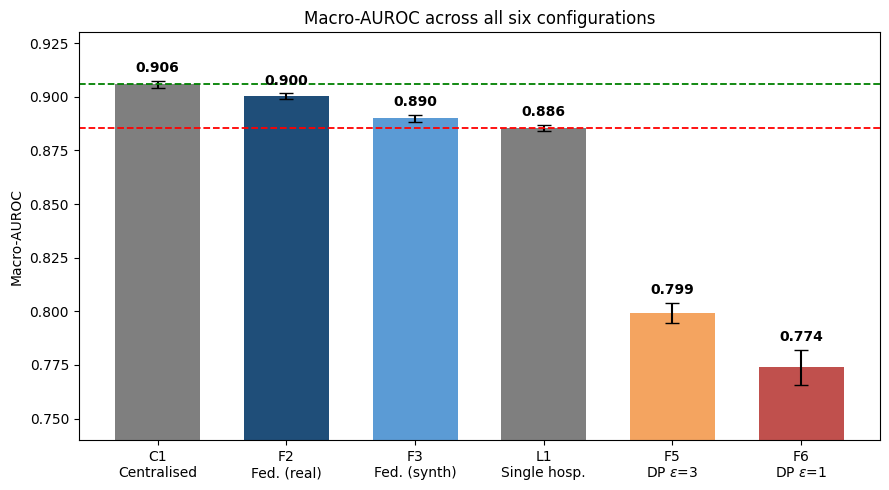

In [9]:
import matplotlib.pyplot as plt
import numpy as np

labels = ['C1\nCentralised', 'F2\nFed. (real)', 'F3\nFed. (synth)',
          'L1\nSingle hosp.', 'F5\nDP $\\epsilon$=3', 'F6\nDP $\\epsilon$=1']
means = [0.9057, 0.9002, 0.8899, 0.8856, 0.7992, 0.7739]
stds = [0.0018, 0.0014, 0.0018, 0.0014, 0.0048, 0.0083]
colors = ['#7f7f7f', '#1f4e79', '#5b9bd5', '#7f7f7f', '#f4a460', '#c0504d']

x = np.arange(6)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, means, yerr=stds, capsize=5, color=colors, width=0.66)
ax.axhline(0.9057, ls='--', color='green', lw=1.3)
ax.axhline(0.8856, ls='--', color='red', lw=1.3)
for xi, m, s in zip(x, means, stds):
    ax.text(xi, m + s + 0.004, f'{m:.3f}', ha='center', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Macro-AUROC')
ax.set_ylim(0.74, 0.93)
ax.set_title('Macro-AUROC across all six configurations')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/ptbxl_cache/fig_all_configs.png', dpi=300, bbox_inches='tight')
plt.show()